## Обучим бейзлайн модели

In [ ]:
!pip install -q catboost

In [ ]:
import pandas as pd
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import roc_auc_score

In [ ]:
url = 'https://raw.githubusercontent.com/totiela/stepik_simulator_ds/main/lessons/lesson_4_1/4_1_churn_dataset.csv'
df = pd.read_csv(url)

df.head()

In [ ]:
# Приводим к типу datetime
target = 'target_churn_next'
cols_to_drop = ['snapshot_month',	'client_id', 'target_churn_next']

# Приводим к дате
df['snapshot_month'] = pd.to_datetime(df['snapshot_month'])

# Вычисляем пороги квантилей по всей колонке
q60 = df['snapshot_month'].quantile(0.60)
q80 = df['snapshot_month'].quantile(0.80)

# Разделяем на три подмножества
# Тренировочная выборка
train_df = df[df['snapshot_month'] <= q60].copy()

# Валидационная выборка - модель оптимизирует метрику на ней
val_df = df[(df['snapshot_month'] > q60) & (df['snapshot_month'] <= q80)].copy()

# out of time выборка, на ней делаем финальную проверку - она наиболее честная
oot_df = df[df['snapshot_month'] > q80].copy()

train_df.shape, val_df.shape, oot_df.shape

In [ ]:
# Формируем матрицы признаков и целевые переменные
X_train = train_df.drop(cols_to_drop, axis=1)
y_train = train_df[target]

X_val = val_df.drop(cols_to_drop, axis=1)
y_val = val_df[target]

X_oot = oot_df.drop(cols_to_drop, axis=1)
y_oot = oot_df[target]

# Создаем Pool-объекты
train_pool = Pool(X_train, label=y_train)
val_pool   = Pool(X_val,  label=y_val)
oot_pool   = Pool(X_oot,  label=y_oot)


In [ ]:
cb_baseline = CatBoostClassifier(
    iterations=600,
    depth=6,
    loss_function='Logloss',
    eval_metric='AUC',
    early_stopping_rounds=75,
    random_state=42,
    verbose=False,
)

cb_baseline.fit(
    train_pool,
    eval_set=val_pool,
    use_best_model=True
)

In [ ]:
# Получаем вероятности положительного класса
# Для CatBoost: predict_proba возвращает вероятности двух классов
train_proba = cb_baseline.predict_proba(train_pool)[:, 1]
val_proba = cb_baseline.predict_proba(val_pool)[:, 1]
oot_proba = cb_baseline.predict_proba(oot_pool)[:, 1]

# Извлечем истинные значения
y_train = train_pool.get_label()
y_val = val_pool.get_label()
y_oot = oot_pool.get_label()

# Рассчитаем ROC AUC
roc_train = roc_auc_score(y_train, train_proba)
roc_val   = roc_auc_score(y_val, val_proba)
roc_oot   = roc_auc_score(y_oot, oot_proba)

# Выводим результаты
print("ROC AUC:")
print(f"  training: {roc_train:.6f}")
print(f"  validation: {roc_val:.6f}")
print(f"  oot: {roc_oot:.6f}")

ROC AUC:
  training: 0.881018
  validation: 0.850689
  oot: 0.842370

## SHAP

### **Как работает SHAP**

**SHAP (SHapley Additive exPlanations)** - метод интерпретации, который раскладывает предсказание модели на вклады отдельных признаков. Он основан на идее *Shapley Values* из теории игр: каждый признак - «игрок», а итоговое предсказание - «выигрыш команды».

### **Основная идея**

SHAP отвечает на вопрос:

> **«Насколько в среднем изменится предсказание модели, если добавить признак *i* к различным комбинациям других признаков?»**

Каждый признак получает свою «долю» влияния.


### **Как это работает**

1. **Моделируем отсутствие признаков.**
   SHAP оценивает предсказание модели, когда часть признаков считается неизвестной (их значения усредняются по распределению данных).

2. **Добавляем интересующий признак.**
   Снова считаем предсказание - теперь с реальным значением признака.

3. **Сравниваем разницу.**
   Разница в предсказании показывает вклад признака для данной комбинации.

4. **Повторяем для множества подмножеств признаков.**
   Это учитывает взаимодействия между признаками.

5. **Усредняем результат.**
   Получаем итоговое **SHAP-значение**, которое увеличивает или уменьшает предсказание относительно среднего значения модели *E[f(X)]*.

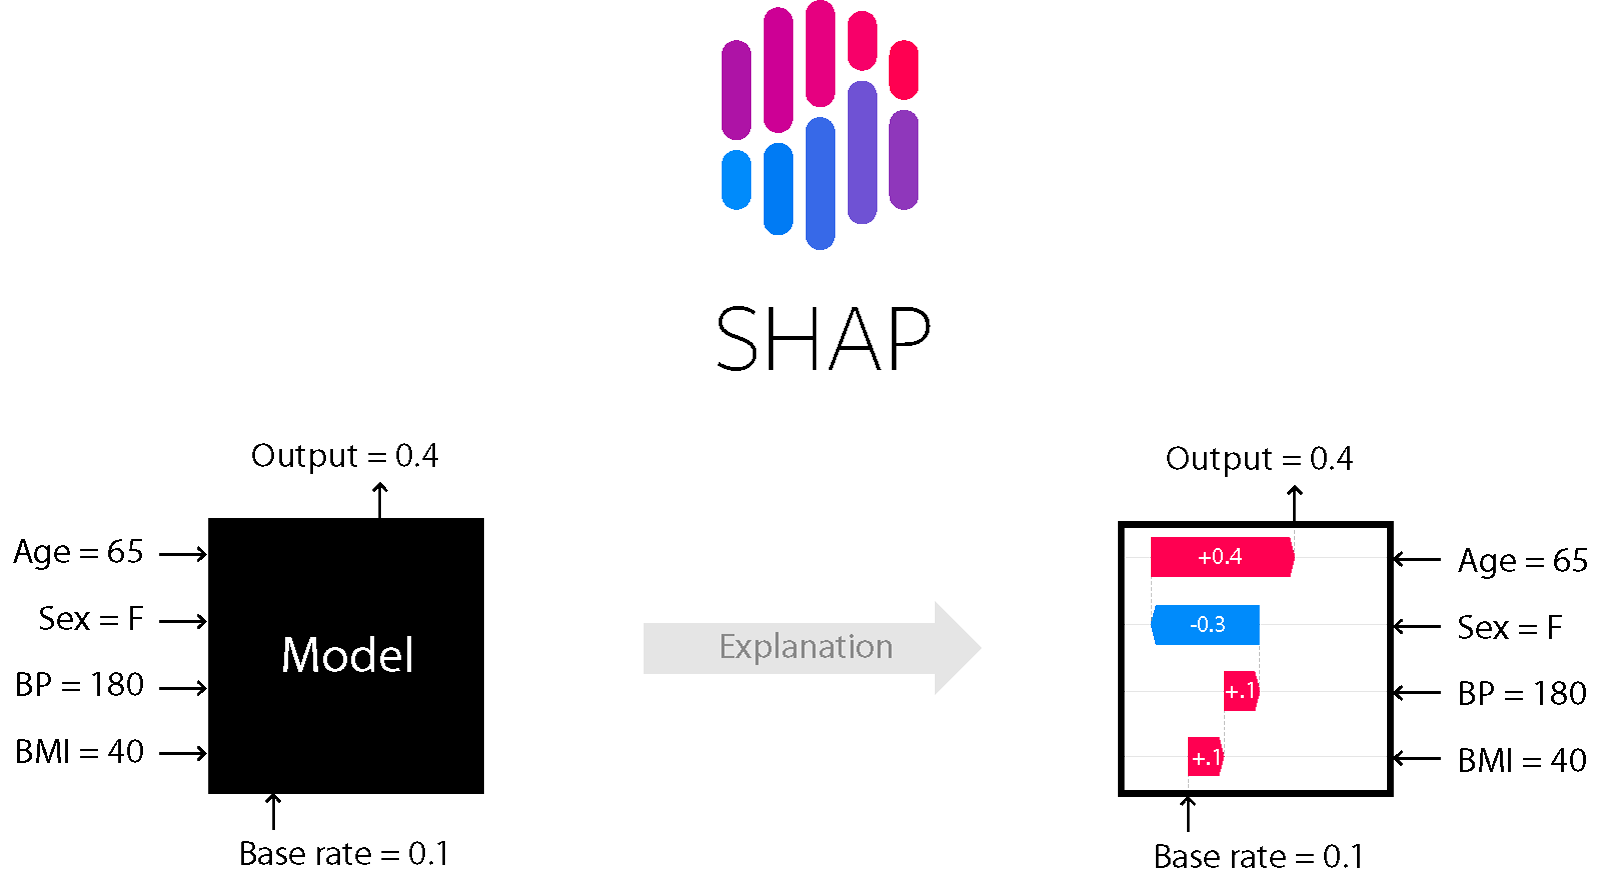

In [ ]:
import shap

# инициализируем специальный объект explainer
explainer = shap.Explainer(cb_baseline)
shap_values = explainer(X_oot)

In [ ]:
# инициализируем строки с отрицательным/положительным классом
neg_idx = 5
pos_idx = 2703

### Диаграмма `waterfall` позволяет визуализировать индивидуальные SHAP-значения каждого образца в наборе данных

In [ ]:
# визуализация SHAP-значений для отрицательного класса
shap.plots.waterfall(shap_values[neg_idx])

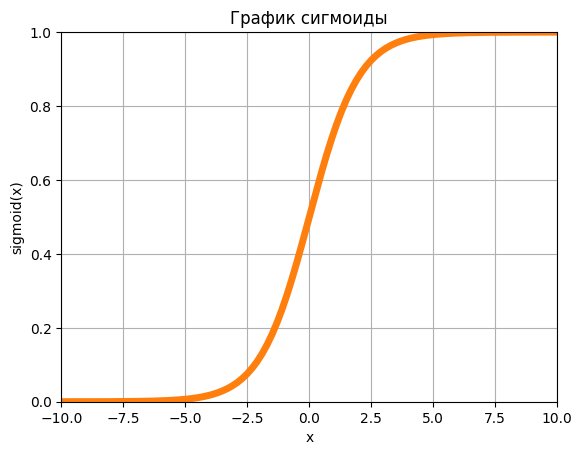

In [ ]:
# визуализация SHAP-значений для положительного класса
shap.plots.waterfall(shap_values[pos_idx])

### Альтернативный вариант - `force`

In [ ]:
shap.initjs()

shap.plots.force(shap_values[neg_idx])

In [ ]:
shap.initjs()

shap.plots.force(shap_values[pos_idx])

### Диаграмма `bar` отражает результаты усреднения SHAP значений по всем наблюдениям

In [ ]:
shap.plots.bar(shap_values)

### beeswarm
Позволяeт визуализировать все SHAP‑значения для каждого признака.
По оси x этой диаграммы SHAP‑значения сгруппированы по признакам. А цвет точек указывает на соответствующее значение признака. Обычно точки, цвет которых ближе к красному, указывают на более высокие значения признаков.

In [ ]:
shap.plots.beeswarm(shap_values)

### Диаграмма scatter
Это диаграмма, которая раскрывает взаимоотношения между SHAP‑значениями и значениями признаков для отдельных признаков.

In [ ]:
shap.plots.scatter(shap_values[:,"risk_score"])